# 03 — Entraînement et évaluation des modèles

**Projet :** Cert_EET — prédiction précoce des apprenants à risque
**Auteur :** Iyed Omri — PFE ESPRIT 2026

## Objectif
Je compare trois approches sur les mêmes données :
1. **Les règles actuelles de Cert_EET**, reproduites sur OULAD. C'est ma **référence** : un modèle
   n'a d'intérêt que s'il fait mieux que ces règles.
2. **Une régression logistique** : modèle simple et facile à expliquer.
3. **Un gradient boosting (LightGBM)** : modèle plus puissant, qui capte des combinaisons de variables.

Tout est reproductible : j'utilise une **graine fixe** (42) pour tous les tirages aléatoires.

In [1]:
import json
import sys
from datetime import date
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RACINE_ML = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "risque").exists())
sys.path.insert(0, str(RACINE_ML))
from risque.variables import VARIABLES

GRAINE = 42
ENTREES = VARIABLES + ["coupure"]   # la date de coupure aide le modèle à lire les compteurs

df = pd.read_csv(RACINE_ML / "donnees" / "variables.csv.gz")
print(df.shape)

(109149, 24)


## 1. Découpage des données : le passé pour apprendre, le futur pour tester

Je **ne mélange pas les lignes au hasard**. Un découpage aléatoire mettrait des apprenants de la même
session à la fois dans l'entraînement et dans le test : le test serait trop facile et ne
ressemblerait pas à l'usage réel.

Je fais un découpage **chronologique** (décidé dans le notebook 01) :
- **entraînement** : sessions 2013B, 2013J et 2014B ;
- **test** : session 2014J, la plus récente. Le modèle ne la voit **jamais** pendant l'entraînement.

Pour choisir les réglages des modèles (hyperparamètres), j'utilise une **validation croisée groupée
par session** sur l'entraînement uniquement : chaque session entière est soit dans la partie
« apprentissage », soit dans la partie « validation », jamais les deux.

In [2]:
est_test = df["code_presentation"] == "2014J"
train, test = df[~est_test].reset_index(drop=True), df[est_test].reset_index(drop=True)

X_train, y_train = train[ENTREES], train["a_risque"]
X_test, y_test = test[ENTREES], test["a_risque"]
groupes = train["code_module"] + "_" + train["code_presentation"]   # une session = un groupe
cv = GroupKFold(n_splits=5)

print(f"Entraînement : {len(train):,} lignes, {groupes.nunique()} sessions, "
      f"{y_train.mean()*100:.1f} % à risque")
print(f"Test (2014J) : {len(test):,} lignes, {y_test.mean()*100:.1f} % à risque")

Entraînement : 72,681 lignes, 15 sessions, 45.4 % à risque
Test (2014J) : 36,468 lignes, 40.2 % à risque


## 2. Modèle (a) : les règles actuelles de Cert_EET

Je reproduis les quatre règles du module `pilotage` de Cert_EET avec mes variables. Une alerte est
levée si **au moins une** règle est vraie :

| Règle Cert_EET | Traduction sur OULAD |
|---|---|
| `INACTIVITE` : aucune connexion depuis plus de 7 jours | `jours_depuis_derniere_activite > 7` |
| `ECHECS_QCM` : les 2 dernières tentatives notées en échec | `echecs_consecutifs_fin >= 2` |
| `LIVRABLE_EN_RETARD` : atelier non rendu après la date limite | `nb_non_rendues >= 1` |
| `SCORE_EN_CHUTE` : dernière note ≤ moyenne des précédentes − 20 (au moins 3 notes) | `tendance_score <= -20` et `nb_notes >= 3` |

Limite : dans Cert_EET, `LIVRABLE_EN_RETARD` attend 48 h après la date limite ; ici je compte toute
évaluation échue non rendue. Les règles donnent une réponse oui/non ; pour calculer les AUC, j'utilise
comme score le **nombre de règles déclenchées** (de 0 à 4).

In [3]:
def regles(t):
    return pd.DataFrame({
        "INACTIVITE": t["jours_depuis_derniere_activite"] > 7,
        "ECHECS_QCM": t["echecs_consecutifs_fin"] >= 2,
        "LIVRABLE_EN_RETARD": t["nb_non_rendues"] >= 1,
        "SCORE_EN_CHUTE": (t["tendance_score"] <= -20) & (t["nb_notes"] >= 3),
    })


def evaluer(nom, y, score, alerte, coupures):
    """Métriques par date de coupure."""
    lignes = []
    for J in sorted(coupures.unique()):
        m = (coupures == J).to_numpy()
        lignes.append({
            "modele": nom, "coupure": J,
            "rappel": recall_score(y[m], alerte[m]),
            "precision": precision_score(y[m], alerte[m]),
            "f1": f1_score(y[m], alerte[m]),
            "roc_auc": roc_auc_score(y[m], score[m]),
            "pr_auc": average_precision_score(y[m], score[m]),
        })
    return pd.DataFrame(lignes)


r_test = regles(test)
print("Part des apprenants concernés par chaque règle (test) :")
print((r_test.mean() * 100).round(1))
res_regles = evaluer("Règles Cert_EET", y_test.to_numpy(), r_test.sum(axis=1).to_numpy(),
                     r_test.any(axis=1).to_numpy().astype(int), test["coupure"])
res_regles.round(3)

Part des apprenants concernés par chaque règle (test) :
INACTIVITE            22.3
ECHECS_QCM             0.1
LIVRABLE_EN_RETARD    11.3
SCORE_EN_CHUTE         0.2
dtype: float64


,modele,coupure,rappel,precision,f1,roc_auc,pr_auc
0,Règles Cert_EET,14,0.277,0.614,0.382,0.576,0.471
1,Règles Cert_EET,28,0.391,0.632,0.484,0.625,0.529
2,Règles Cert_EET,42,0.510,0.616,0.558,0.665,0.556
3,Règles Cert_EET,56,0.579,0.633,0.605,0.704,0.590


## 3. Modèles (b) et (c) : régression logistique et LightGBM

**Régression logistique.** Elle ne sait pas gérer les valeurs vides : je remplace une note manquante par
la médiane (calculée sur l'entraînement seulement). L'indicateur `a_au_moins_une_note` garde l'information
« pas encore de note ». Je mets aussi les variables à la même échelle (normalisation), sinon une
variable en jours pèserait artificiellement plus qu'un taux entre 0 et 1.

**LightGBM.** Il gère les valeurs vides tout seul et n'a pas besoin de normalisation. J'active le mode
déterministe pour obtenir exactement les mêmes résultats à chaque exécution.

Je choisis les réglages qui maximisent la **PR-AUC** en validation croisée groupée.

In [4]:
logreg = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("normalisation", StandardScaler()),
    ("modele", LogisticRegression(max_iter=2000)),
])
recherche_lr = GridSearchCV(logreg, {"modele__C": [0.01, 0.1, 1, 10]},
                            scoring="average_precision", cv=cv, n_jobs=-1)
recherche_lr.fit(X_train, y_train, groups=groupes)

lgbm = LGBMClassifier(random_state=GRAINE, deterministic=True, force_col_wise=True,
                      n_jobs=1, verbose=-1)
grille = {"num_leaves": [15, 31], "n_estimators": [200, 400],
          "learning_rate": [0.05], "min_child_samples": [50]}
recherche_gb = GridSearchCV(lgbm, grille, scoring="average_precision", cv=cv, n_jobs=-1)
recherche_gb.fit(X_train, y_train, groups=groupes)

for nom, r in [("Régression logistique", recherche_lr), ("LightGBM", recherche_gb)]:
    print(f"{nom:22} PR-AUC validation croisée = {r.best_score_:.3f}  réglages = {r.best_params_}")

Régression logistique  PR-AUC validation croisée = 0.731  réglages = {'modele__C': 0.01}
LightGBM               PR-AUC validation croisée = 0.740  réglages = {'learning_rate': 0.05, 'min_child_samples': 50, 'n_estimators': 200, 'num_leaves': 15}


## 4. Choix du seuil de décision

Le modèle donne une probabilité ; je dois choisir à partir de quelle probabilité j'envoie une alerte.
Comme un apprenant manqué coûte plus cher qu'une fausse alerte, je vise un **rappel d'au moins 80 %**.

Point important : je choisis ce seuil **sans regarder le test**. J'utilise les prédictions de la
validation croisée sur l'entraînement (prédictions « hors échantillon »), puis je garde le seuil le
plus haut qui atteint 80 % de rappel. Choisir le seuil sur le test reviendrait à tricher.

In [5]:
RAPPEL_CIBLE = 0.80

def seuil_pour_rappel(y, proba, cible=RAPPEL_CIBLE):
    _, rappel, seuils = precision_recall_curve(y, proba)
    return float(seuils[rappel[:-1] >= cible].max())

modeles = {"Régression logistique": recherche_lr.best_estimator_,
           "LightGBM": recherche_gb.best_estimator_}
seuils, resultats = {}, [res_regles]
for nom, m in modeles.items():
    oof = cross_val_predict(m, X_train, y_train, groups=groupes, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
    seuils[nom] = seuil_pour_rappel(y_train, oof)
    proba = m.predict_proba(X_test)[:, 1]
    resultats.append(evaluer(nom, y_test.to_numpy(), proba,
                             (proba >= seuils[nom]).astype(int), test["coupure"]))
    print(f"{nom:22} seuil retenu = {seuils[nom]:.3f}")

Régression logistique  seuil retenu = 0.356
LightGBM               seuil retenu = 0.355


## 5. Résultats sur le test (session 2014J, jamais vue)

In [6]:
tous = pd.concat(resultats, ignore_index=True)
for metrique in ["rappel", "precision", "f1", "roc_auc", "pr_auc"]:
    print(f"\n=== {metrique} ===")
    print(tous.pivot(index="modele", columns="coupure", values=metrique).round(3))


=== rappel ===
coupure                   14     28     42     56
modele                                           
LightGBM               0.868  0.757  0.732  0.789
Règles Cert_EET        0.277  0.391  0.510  0.579
Régression logistique  0.866  0.754  0.696  0.730

=== precision ===
coupure                   14     28     42     56
modele                                           
LightGBM               0.476  0.544  0.569  0.560
Règles Cert_EET        0.614  0.632  0.616  0.633
Régression logistique  0.471  0.537  0.575  0.585

=== f1 ===
coupure                   14     28     42     56
modele                                           
LightGBM               0.615  0.633  0.640  0.655
Règles Cert_EET        0.382  0.484  0.558  0.605
Régression logistique  0.610  0.627  0.630  0.650

=== roc_auc ===
coupure                   14     28     42     56
modele                                           
LightGBM               0.657  0.715  0.740  0.778
Règles Cert_EET        0.576  0.625 

## 6. Matrice de confusion et calibration du modèle retenu

Je retiens le modèle qui a la meilleure PR-AUC **en validation croisée** (et non sur le test, pour
ne pas biaiser mon choix).

- La **matrice de confusion** à J+28 montre concrètement combien d'apprenants sont détectés, manqués,
  ou signalés à tort.
- La **calibration** vérifie qu'une probabilité de 70 % correspond bien à environ 70 % d'apprenants
  réellement à risque. C'est important car le formateur verra ce pourcentage.

Modèle retenu : LightGBM | seuil : 0.355

J+28 — détectés : 2846, manqués : 912, fausses alertes : 2388, correctement non signalés : 3068
Score de Brier : 0.215 (0 = parfait)


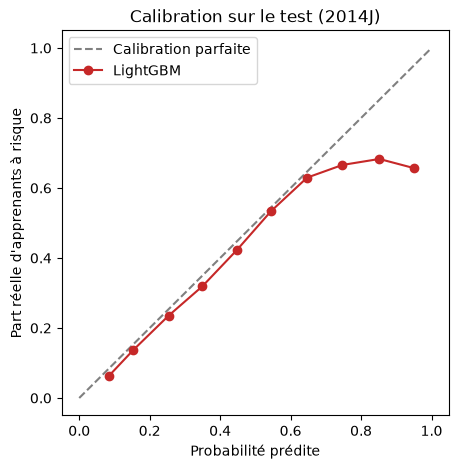

In [7]:
nom_final = max(modeles, key=lambda n: (recherche_lr if n.startswith("Régression") else recherche_gb).best_score_)
final, seuil_final = modeles[nom_final], seuils[nom_final]
print("Modèle retenu :", nom_final, "| seuil :", round(seuil_final, 3))

proba_test = final.predict_proba(X_test)[:, 1]
m28 = (test["coupure"] == 28).to_numpy()
vn, fp, fn, vp = confusion_matrix(y_test[m28], (proba_test[m28] >= seuil_final).astype(int)).ravel()
print(f"\nJ+28 — détectés : {vp}, manqués : {fn}, fausses alertes : {fp}, correctement non signalés : {vn}")

frac_pos, proba_moy = calibration_curve(y_test, proba_test, n_bins=10)
print(f"Score de Brier : {brier_score_loss(y_test, proba_test):.3f} (0 = parfait)")
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", color="grey", label="Calibration parfaite")
plt.plot(proba_moy, frac_pos, "o-", color="#c62828", label=nom_final)
plt.xlabel("Probabilité prédite")
plt.ylabel("Part réelle d'apprenants à risque")
plt.title("Calibration sur le test (2014J)")
plt.legend()
plt.show()

### Mes constats sur les résultats

**1. Le modèle détecte 2 à 3 fois plus d'apprenants à risque que les règles actuelles.**
À J+14, LightGBM repère **87 %** des apprenants à risque, contre **28 %** pour les règles. L'écart est
le plus grand au début de la session, justement quand une intervention est la plus utile. Les deux
règles basées sur les notes (`ECHECS_QCM`, `SCORE_EN_CHUTE`) ne se déclenchent presque jamais tôt
(0,1 % et 0,2 % des apprenants) : il y a encore trop peu de notes.

**2. Le prix à payer : plus de fausses alertes.** La précision du modèle est d'environ 0,5 : environ une
alerte sur deux concerne un apprenant réellement à risque, contre environ six sur dix pour les règles.
À J+28, sur la session de test : **2 846 apprenants détectés, 912 manqués, 2 388 fausses alertes**.
C'est le compromis que j'ai choisi, car un apprenant manqué coûte plus cher qu'un message inutile. Le F1,
la ROC-AUC et la PR-AUC sont meilleurs que ceux des règles **à toutes les dates**.

**3. L'objectif de 80 % de rappel n'est pas atteint partout.** Il est dépassé à J+14 (87 %), mais pas à
J+28 (76 %), J+42 (73 %) et J+56 (79 %). Explication : j'ai fixé le seuil sur les sessions
d'entraînement (45,4 % d'apprenants à risque), alors que la session de test en compte moins (40,2 %).
Je préfère le constater honnêtement plutôt que d'ajuster le seuil sur le test, ce qui fausserait
l'évaluation.

**4. La régression logistique est presque aussi bonne.** PR-AUC en validation croisée : 0,740 pour
LightGBM contre 0,731. J'ai retenu LightGBM selon la règle fixée à l'avance (meilleure PR-AUC en
validation croisée). L'écart étant faible, la régression logistique reste une alternative valable si
l'on privilégie la simplicité.

**5. Une performance moyenne, mais assumée.** Une ROC-AUC de 0,66 à 0,78 est modeste. C'est le prix de
mon choix de n'utiliser **que des variables transposables à Cert_EET** : ni le volume de clics, ni les
variables personnelles. Un modèle plus performant sur OULAD, mais inutilisable dans Cert_EET, n'aurait
pas d'intérêt pour mon projet.

**6. Calibration : fiable jusqu'à environ 65 %.** Jusqu'à 0,65, la probabilité prédite correspond bien
à la réalité. Au-delà, le modèle est trop sûr de lui : une probabilité de 0,85 correspond en réalité à
environ 68 % d'apprenants à risque. Score de Brier : 0,215 (contre 0,240 pour une prédiction constante).
**Ma décision :** l'interface affichera un **niveau de risque** (faible, moyen, élevé) plutôt qu'un
pourcentage exact, et le formateur gardera toujours la décision.

## 7. Sauvegarde du modèle

J'enregistre le modèle retenu et sa **fiche technique** (variables attendues, seuil, réglages,
résultats, versions des bibliothèques). Le service `ml` chargera ces deux fichiers.

In [8]:
dossier = RACINE_ML / "modeles"
dossier.mkdir(exist_ok=True)
joblib.dump(final, dossier / "risque_v1.joblib")

fiche = {
    "version": "risque_v1",
    "date_entrainement": date.today().isoformat(),
    "modele": nom_final,
    "entrees": ENTREES,
    "seuil": round(seuil_final, 4),
    "rappel_cible": RAPPEL_CIBLE,
    "graine": GRAINE,
    "reglages": (recherche_lr if nom_final.startswith("Régression") else recherche_gb).best_params_,
    "donnees": "OULAD (Kuzilek et al., 2017, CC BY 4.0)",
    "decoupage": {"entrainement": ["2013B", "2013J", "2014B"], "test": ["2014J"]},
    "resultats_test": tous[tous["modele"] == nom_final].round(4).to_dict(orient="records"),
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "lightgbm": lightgbm.__version__, "pandas": pd.__version__},
}
(dossier / "risque_v1.json").write_text(json.dumps(fiche, indent=2, ensure_ascii=False), encoding="utf-8")
print("Enregistré :", list(p.name for p in dossier.iterdir()))

Enregistré : ['risque_v1.joblib', 'risque_v1.json']
